In [2]:
%pip install pandas numpy matplotlib scipy scikit-learn requests seaborn

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 6.6 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.7/37.7 MB 4.5 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 8.1 MB/s eta 0:00:00:00:010:01m
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 KB 3.6 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 306.1/306.1 KB 2.9 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy
import sklearn
import requests
import seaborn as sns

print("Toutes les bibliothèques sont installées !")

Toutes les bibliothèques sont installées !


In [6]:
df = pd.read_csv("seance1.csv")

In [9]:
df.shape

(28, 6)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   timestamp    28 non-null     object 
 1   minute       28 non-null     int64  
 2   duree_s      28 non-null     int64  
 3   heart_rate   28 non-null     int64  
 4   speed_kmh    28 non-null     float64
 5   distance_km  28 non-null     float64
dtypes: float64(2), int64(3), object(1)
memory usage: 1.4+ KB


In [12]:
df.isnull().sum()

timestamp      0
minute         0
duree_s        0
heart_rate     0
speed_kmh      0
distance_km    0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
print("Vitesses négatives :", (df["speed_kmh"] < 0).sum())

print("FC invalides :", (df["heart_rate"] <= 0).sum())

print("Durées invalides :", (df["duree_s"] <= 0).sum())

Vitesses négatives : 0
FC invalides : 0
Durées invalides : 0


In [15]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

In [16]:
print(df["timestamp"].is_monotonic_increasing)

True


In [17]:
print("Horodatages identiques :", df["timestamp"].duplicated().sum())


Horodatages identiques : 0


In [18]:
print("Distances qui diminuent :", (df["distance_km"].diff() < 0).sum())

Distances qui diminuent : 0


In [19]:
df["temps_ecoule"] = df["timestamp"].diff().dt.total_seconds()

print(df[["timestamp", "duree_s", "temps_ecoule"]])

             timestamp  duree_s  temps_ecoule
0  2026-10-08 14:57:00       60           NaN
1  2026-10-08 14:58:00       60          60.0
2  2026-10-08 14:59:00       60          60.0
3  2026-10-08 15:00:00       60          60.0
4  2026-10-08 15:01:00       60          60.0
5  2026-10-08 15:02:00       60          60.0
6  2026-10-08 15:03:00       60          60.0
7  2026-10-08 15:04:00       60          60.0
8  2026-10-08 15:05:00       60          60.0
9  2026-10-08 15:06:00       60          60.0
10 2026-10-08 15:07:00       60          60.0
11 2026-10-08 15:08:00       60          60.0
12 2026-10-08 15:09:00       60          60.0
13 2026-10-08 15:10:00       60          60.0
14 2026-10-08 15:11:00       60          60.0
15 2026-10-08 15:12:00       60          60.0
16 2026-10-08 15:13:00       60          60.0
17 2026-10-08 15:14:00       60          60.0
18 2026-10-08 15:15:00       60          60.0
19 2026-10-08 15:16:00       60          60.0
20 2026-10-08 15:17:00       60   

         BILAN DE LA SEANCE

--- INFORMATIONS GENERALES ---
Nombre de mesures : 28
Duree totale : 27 min 24 s
Distance totale : 5.000 km

--- FREQUENCE CARDIAQUE ---
FC moyenne : 154.46 bpm
FC minimale : 96 bpm
FC maximale : 166 bpm
Ecart-type FC : 16.84 bpm

--- VITESSE ---
Vitesse moyenne : 10.95 km/h
Vitesse minimale : 7.14 km/h
Vitesse maximale : 12.10 km/h
Ecart-type vitesse : 1.17 km/h
Coefficient de variation : 10.71 %

--- ALLURE ---
Allure moyenne : 5:29 min/km

--- RELATION FC / VITESSE ---
Correlation : 0.852


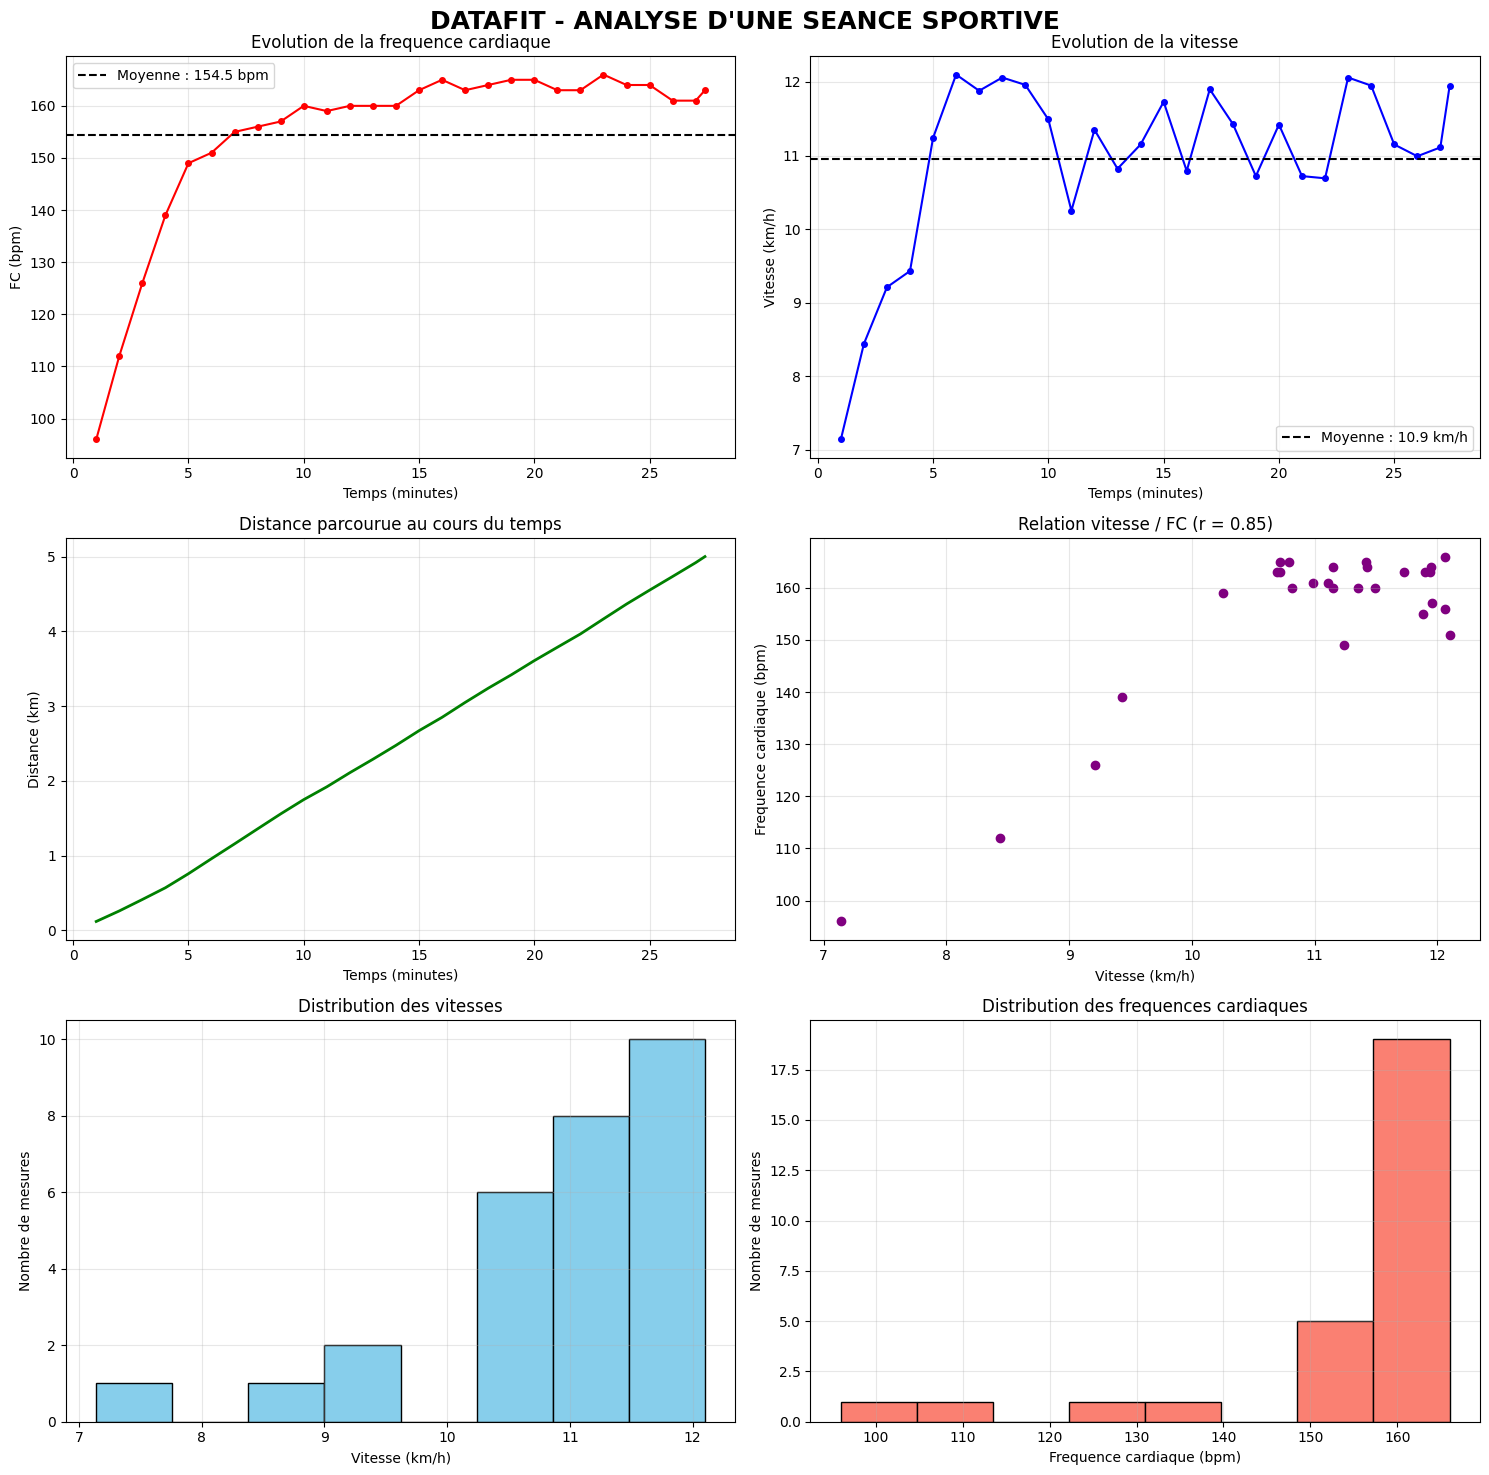

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("seance1.csv")
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["temps_min"] = df["duree_s"].cumsum() / 60

df["distance_intervalle"] = df["distance_km"].diff()
df.loc[df.index[0], "distance_intervalle"] = df.loc[df.index[0], "distance_km"]

duree_secondes = df["duree_s"].sum()
duree_minutes = duree_secondes / 60

minutes = int(duree_secondes // 60)
secondes = int(duree_secondes % 60)

distance_totale = df["distance_km"].iloc[-1]
nombre_mesures = len(df)

fc_moyenne = (df["heart_rate"] * df["duree_s"]).sum() / duree_secondes
fc_min = df["heart_rate"].min()
fc_max = df["heart_rate"].max()
fc_ecart_type = df["heart_rate"].std()

vitesse_moyenne = distance_totale / (duree_secondes / 3600)
vitesse_min = df["speed_kmh"].min()
vitesse_max = df["speed_kmh"].max()
vitesse_ecart_type = df["speed_kmh"].std()

if vitesse_moyenne > 0:
    regularite = (vitesse_ecart_type / vitesse_moyenne) * 100
else:
    regularite = np.nan

if distance_totale > 0:
    allure_secondes = duree_secondes / distance_totale
    allure_min = int(allure_secondes // 60)
    allure_sec = int(round(allure_secondes % 60))

    if allure_sec == 60:
        allure_min += 1
        allure_sec = 0

    allure = f"{allure_min}:{allure_sec:02d} min/km" #combien de secondes pour parcourir 1km
else:
    allure = "Non disponible"

correlation = df["heart_rate"].corr(df["speed_kmh"]) #relation linéaire entre deux variables

print("=" * 45)
print("         BILAN DE LA SEANCE")
print("=" * 45)

print("\n--- INFORMATIONS GENERALES ---")
print("Nombre de mesures :", nombre_mesures)
print(f"Duree totale : {minutes} min {secondes} s")
print(f"Distance totale : {distance_totale:.3f} km")

print("\n--- FREQUENCE CARDIAQUE ---")
print(f"FC moyenne : {fc_moyenne:.2f} bpm")
print(f"FC minimale : {fc_min} bpm")
print(f"FC maximale : {fc_max} bpm")
print(f"Ecart-type FC : {fc_ecart_type:.2f} bpm")

print("\n--- VITESSE ---")
print(f"Vitesse moyenne : {vitesse_moyenne:.2f} km/h")
print(f"Vitesse minimale : {vitesse_min:.2f} km/h")
print(f"Vitesse maximale : {vitesse_max:.2f} km/h")
print(f"Ecart-type vitesse : {vitesse_ecart_type:.2f} km/h")
print(f"Coefficient de variation : {regularite:.2f} %")

print("\n--- ALLURE ---")
print("Allure moyenne :", allure)

print("\n--- RELATION FC / VITESSE ---")
print(f"Correlation : {correlation:.3f}")

fig, axes = plt.subplots(3, 2, figsize=(15, 15))

fig.suptitle(
    "DATAFIT - ANALYSE D'UNE SEANCE SPORTIVE",
    fontsize=18,
    fontweight="bold"
)

axes[0, 0].plot(
    df["temps_min"],
    df["heart_rate"],
    color="red",
    marker="o",
    markersize=4
)

axes[0, 0].axhline(
    fc_moyenne,
    color="black",
    linestyle="--",
    label=f"Moyenne : {fc_moyenne:.1f} bpm"
)

axes[0, 0].set_title("Evolution de la frequence cardiaque")
axes[0, 0].set_xlabel("Temps (minutes)")
axes[0, 0].set_ylabel("FC (bpm)")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

axes[0, 1].plot(
    df["temps_min"],
    df["speed_kmh"],
    color="blue",
    marker="o",
    markersize=4
)

axes[0, 1].axhline(
    vitesse_moyenne,
    color="black",
    linestyle="--",
    label=f"Moyenne : {vitesse_moyenne:.1f} km/h"
)

axes[0, 1].set_title("Evolution de la vitesse")
axes[0, 1].set_xlabel("Temps (minutes)")
axes[0, 1].set_ylabel("Vitesse (km/h)")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

axes[1, 0].plot(
    df["temps_min"],
    df["distance_km"],
    color="green",
    linewidth=2
)

axes[1, 0].set_title("Distance parcourue au cours du temps")
axes[1, 0].set_xlabel("Temps (minutes)")
axes[1, 0].set_ylabel("Distance (km)")
axes[1, 0].grid(alpha=0.3)

axes[1, 1].scatter(
    df["speed_kmh"],
    df["heart_rate"],
    color="purple"
)

axes[1, 1].set_title(
    f"Relation vitesse / FC (r = {correlation:.2f})"
)

axes[1, 1].set_xlabel("Vitesse (km/h)")
axes[1, 1].set_ylabel("Frequence cardiaque (bpm)")
axes[1, 1].grid(alpha=0.3)

axes[2, 0].hist(
    df["speed_kmh"],
    bins=8,
    color="skyblue",
    edgecolor="black"
)

axes[2, 0].set_title("Distribution des vitesses")
axes[2, 0].set_xlabel("Vitesse (km/h)")
axes[2, 0].set_ylabel("Nombre de mesures")
axes[2, 0].grid(alpha=0.3)

axes[2, 1].hist(
    df["heart_rate"],
    bins=8,
    color="salmon",
    edgecolor="black"
)

axes[2, 1].set_title("Distribution des frequences cardiaques")
axes[2, 1].set_xlabel("Frequence cardiaque (bpm)")
axes[2, 1].set_ylabel("Nombre de mesures")
axes[2, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()